# 11D — NFL athletic development across seasons

**Hypothesis (S11D, descriptive).** Athletes differ measurably in how their game movement characteristics change after entering the NFL: the between-athlete SD of the per-year slope is larger than zero beyond measurement noise.

**Panel (D1).** One row per athlete × season × trait: speed-band accelerations, acceleration from low speed, observed top speed, braking, re-acceleration, per-season envelope A0 / V0 (11B), exposure-adjusted burst and high-speed frequencies, movement diversity (entropy of the demand mix). Time axis = years since the draft (age is not in the warehouse).

**Models (D3).** Within-athlete change (first → last season, OLS and Theil–Sen slopes), position × season adjustment, a random-intercept + random-slope mixed model fitted by EM with an athlete-bootstrap interval for the slope SD, by position where supported. Selection into later seasons and differing observation horizons are reported, not ignored.

**Not claimed.** A change with time in the league is not a training effect; tracking or role changes between seasons are alternative explanations.

**NOT_FEASIBLE branch.** When too few athletes have ≥ 2 supported seasons, the notebook switches to a within-season alternative (first vs second half of each season's games).

**Prerequisites.** 11.0, 11B.

In [1]:
RUN_MODE = 'full'
SEED = 20261011
FORCE_REBUILD = False
SAVE_TABLES = True
SAVE_FIGURES = True
NUM_WORKERS = 0
N_BOOT_LMM = 200              # athlete-bootstrap replicates of the slope SD (each refits the EM model)

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement.artifacts import DiscoveryStore
from nflbdb.research.advanced_movement.m11 import assemble as asm
from nflbdb.research.advanced_movement.m11 import combine_drills as cd
from nflbdb.research.advanced_movement.m11 import config as m11c
from nflbdb.research.advanced_movement.m11 import development as dv
from nflbdb.research.advanced_movement.m11 import figures as fg
from nflbdb.research.advanced_movement.m11 import reporting as rp
from nflbdb.research.advanced_movement.m11 import sources as src
from nflbdb.research.advanced_movement.m11 import tournament as tn

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
store = DiscoveryStore(cfg, controls)
amc.seed_everything(controls.seed)
C = m11c.M11Config().for_mode(controls)
S = src.M11Sources(cfg, store, C)
PROV = m11c.provenance('11D', controls, C)
W = store.write_frame
episodes = S.episodes()
plays = S.plays()
pairs = asm.foundation(store, 'm11_brake_reaccel_pairs')
officials = asm.foundation(store, 'm11_officials')
env_season = store.read_frame('m11_envelopes_season', src.NB['11B']) if store.has('m11_envelopes_season') else None
label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
seasons = sorted(episodes['season'].unique().to_list())
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · seasons in the episodes: {seasons}'))

**Run mode: `full`** (FULL) · seasons in the episodes: [2023, 2024, 2025]

## 1 · Longitudinal panel and feasibility

A trait-season is `supported` with ≥ `min_episodes_season` episodes (rates: ≥ 5 × that many eligible plays). Feasibility per trait = athletes with ≥ `min_seasons` supported seasons.

In [3]:
panel = dv.position_adjust(dv.season_panel(episodes, pairs, plays, officials, env_season, C))
feas = dv.feasibility(panel, C)
W(panel, 'm11_season_panel', csv=False)
W(feas, 'm11_development_feasibility')
with pl.Config(tbl_rows=-1, tbl_width_chars=200):
    display(feas)
    display(panel.group_by('season').agg(pl.col('nfl_id').n_unique().alias('athletes'), pl.col('draft_year').min().alias('earliest_draft'), pl.col('draft_year').max().alias('latest_draft')).sort('season'))
hor = officials.group_by('draft_year').agg(pl.len().alias('athletes')).with_columns((max(seasons) - pl.col('draft_year') + 1).alias('max_seasons_observable')).sort('draft_year') if seasons else pl.DataFrame()
display(hor)
FEASIBLE = feas.filter(pl.col('state') != m11c.NOT_FEASIBLE)['trait'].to_list()
print('traits with multi-season support:', FEASIBLE or 'none — the within-season alternative is used')

trait,n_athletes_multi_season,n_athletes_ge3,n_athletes_any,state
str,i64,i64,i64,str
"""env.lin_A0""",207,83,388,"""SUPPORTED"""
"""env.lin_V0""",206,83,386,"""SUPPORTED"""
"""nfl.accel_low_mean""",207,84,385,"""SUPPORTED"""
"""nfl.band_4_6""",136,55,267,"""SUPPORTED"""
"""nfl.band_6_8""",65,20,129,"""SUPPORTED"""
"""nfl.brake_decel""",179,75,338,"""SUPPORTED"""
"""nfl.burst_per_100_plays""",180,71,334,"""SUPPORTED"""
"""nfl.high_speed_per_100_plays""",180,71,334,"""SUPPORTED"""
"""nfl.movement_diversity""",187,79,362,"""SUPPORTED"""


season,athletes,earliest_draft,latest_draft
i64,u32,i64,i64
2023,122,2023,2023
2024,247,2023,2024
2025,353,2023,2025


draft_year,athletes,max_seasons_observable
i64,u32,i64
2023,160,3
2024,177,2
2025,173,1


traits with multi-season support: ['env.lin_A0', 'env.lin_V0', 'nfl.accel_low_mean', 'nfl.band_4_6', 'nfl.band_6_8', 'nfl.brake_decel', 'nfl.burst_per_100_plays', 'nfl.high_speed_per_100_plays', 'nfl.movement_diversity', 'nfl.reaccel_mean', 'nfl.vmax_p90']


## 2 · Development characteristics and models

trait,intercept,slope,sd_intercept,sd_slope,corr_int_slope,sd_residual,loglik,n_athletes,n_obs,sd_slope_lo,sd_slope_hi,status
str,f64,f64,f64,f64,f64,f64,f64,i64,i64,f64,f64,str
"""env.lin_A0""",-0.00441,-0.024401,0.495495,0.060049,-0.836668,0.251565,-247.902338,207,497,0.033878,0.059673,"""computed"""
"""env.lin_V0""",-1.932404,3.959779,8.887746,0.031692,0.061292,37.92523,-2514.625798,206,495,0.031629,0.032226,"""computed"""
"""nfl.accel_low_mean""",-0.007949,0.013326,0.167923,0.035064,-0.580954,0.089769,264.972245,207,498,0.024815,0.051517,"""computed"""
"""nfl.band_4_6""",0.037898,-0.011951,0.186199,0.024983,-0.320564,0.12556,90.810694,136,327,0.023379,0.040254,"""computed"""
"""nfl.band_6_8""",0.047631,-0.026207,0.15516,0.021528,-0.628397,0.095537,78.570822,65,150,0.019761,0.041332,"""computed"""
"""nfl.brake_decel""",-0.033262,-0.007473,0.130813,0.038986,-0.448385,0.155973,104.288552,179,433,0.027515,0.049031,"""computed"""
"""nfl.burst_per_100_plays""",-0.386758,0.414844,9.271744,0.031623,0.002359,7.103143,-1601.653509,180,431,0.031622,0.031686,"""computed"""
"""nfl.high_speed_per_100_plays""",-0.132865,-0.282733,3.763438,0.033464,-0.32697,3.272289,-1249.625799,180,431,0.031623,0.032562,"""computed"""
"""nfl.movement_diversity""",0.031701,-0.001635,0.115299,0.012127,0.23743,0.062195,401.242574,187,453,0.014007,0.02479,"""computed"""


trait,n_athletes,spearman,spearman_lo,spearman_hi
str,i64,f64,f64,f64
"""env.lin_A0""",207,0.946239,0.922517,0.959767
"""env.lin_V0""",206,0.673672,0.579169,0.762863
"""nfl.accel_low_mean""",207,0.946017,0.92697,0.958579
"""nfl.band_4_6""",136,0.931215,0.898827,0.951618
"""nfl.band_6_8""",65,0.618269,0.44802,0.768375
"""nfl.brake_decel""",179,0.780667,0.702296,0.843593
"""nfl.burst_per_100_plays""",180,0.858026,0.805442,0.904407
"""nfl.high_speed_per_100_plays""",180,0.942339,0.919539,0.957543
"""nfl.movement_diversity""",187,0.937532,0.909102,0.957733


trait,multi_season,n_athletes,first_value_median,draft_year_median,forty.band_4_6_mean_accel_median,forty.phase_A0_median,forty.v_max_obs_median
str,bool,u32,f64,f64,f64,f64,f64
"""env.lin_A0""",false,181,5.216795,2025.0,4.70453,6.87666,10.538897
"""env.lin_A0""",true,207,5.488734,2023.0,5.214217,7.454659,10.708748
"""env.lin_V0""",false,180,11.789309,2025.0,4.702379,6.894737,10.534266
"""env.lin_V0""",true,206,11.585373,2023.0,5.226039,7.437546,10.714535
"""nfl.accel_low_mean""",false,178,2.733914,2025.0,4.70668,6.858583,10.543527
"""nfl.accel_low_mean""",true,207,2.831687,2023.0,5.214217,7.454659,10.708748
"""nfl.band_4_6""",false,131,3.207094,2025.0,4.933144,7.147519,10.744198
"""nfl.band_4_6""",true,136,3.308426,2023.0,5.459348,7.593238,10.857746
"""nfl.band_6_8""",false,64,2.386576,2025.0,5.347113,7.46451,11.092795


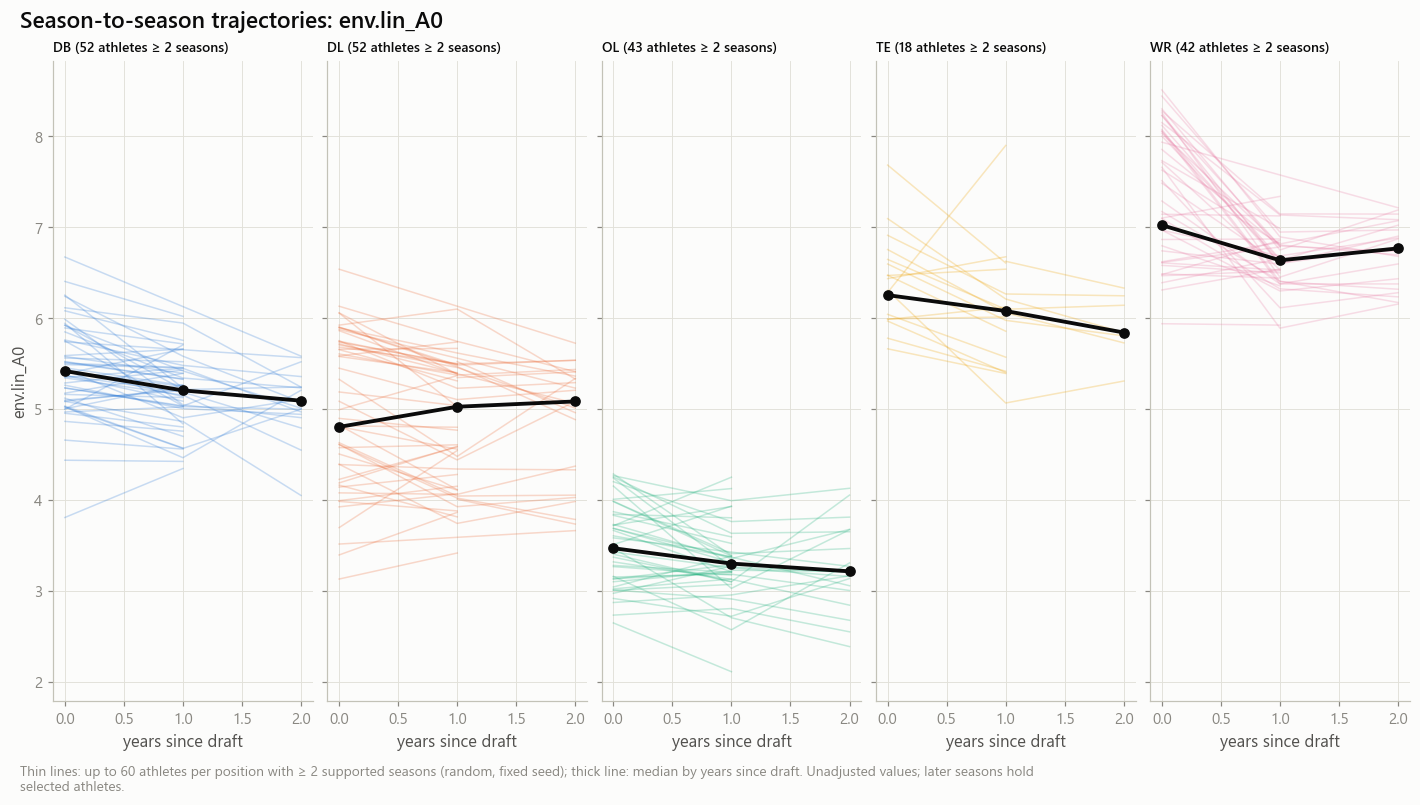

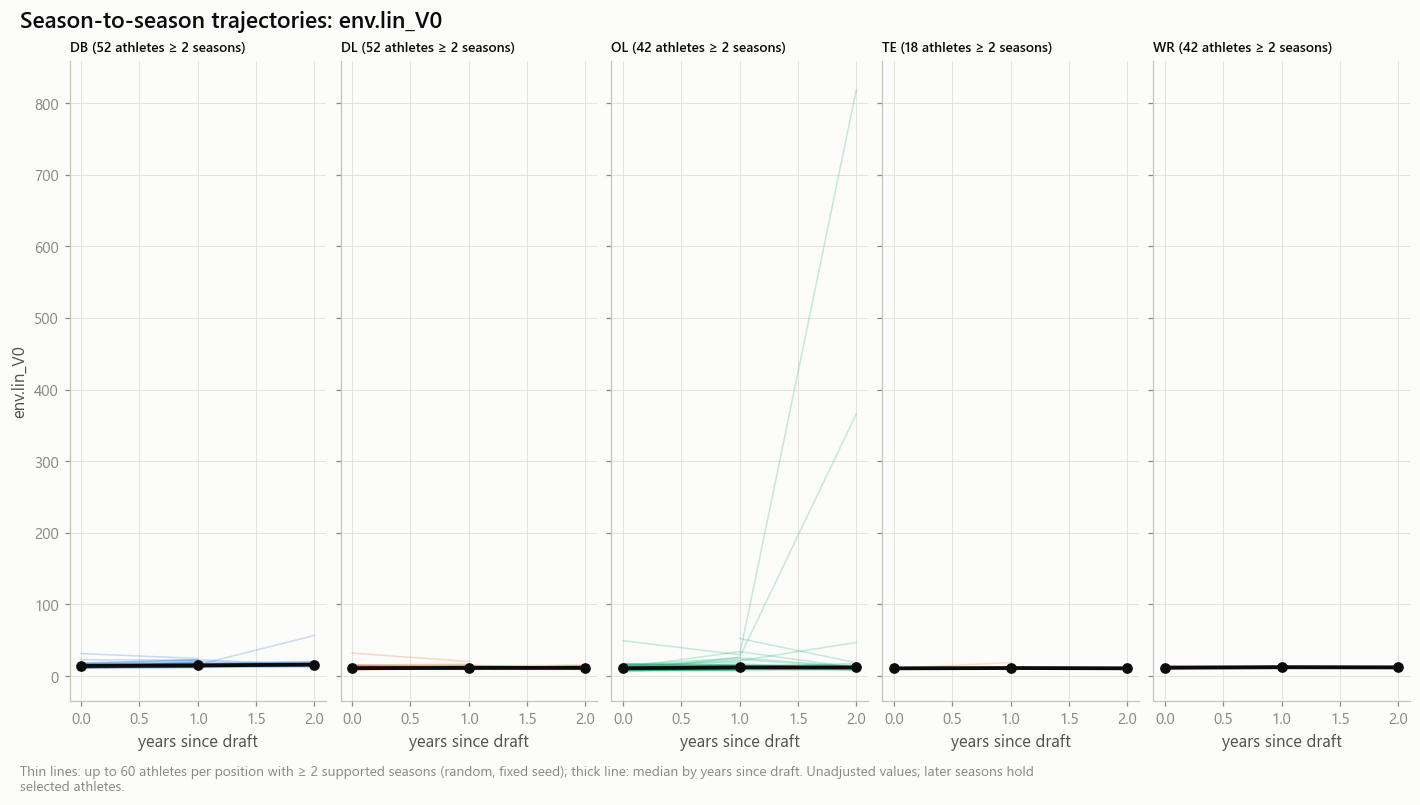

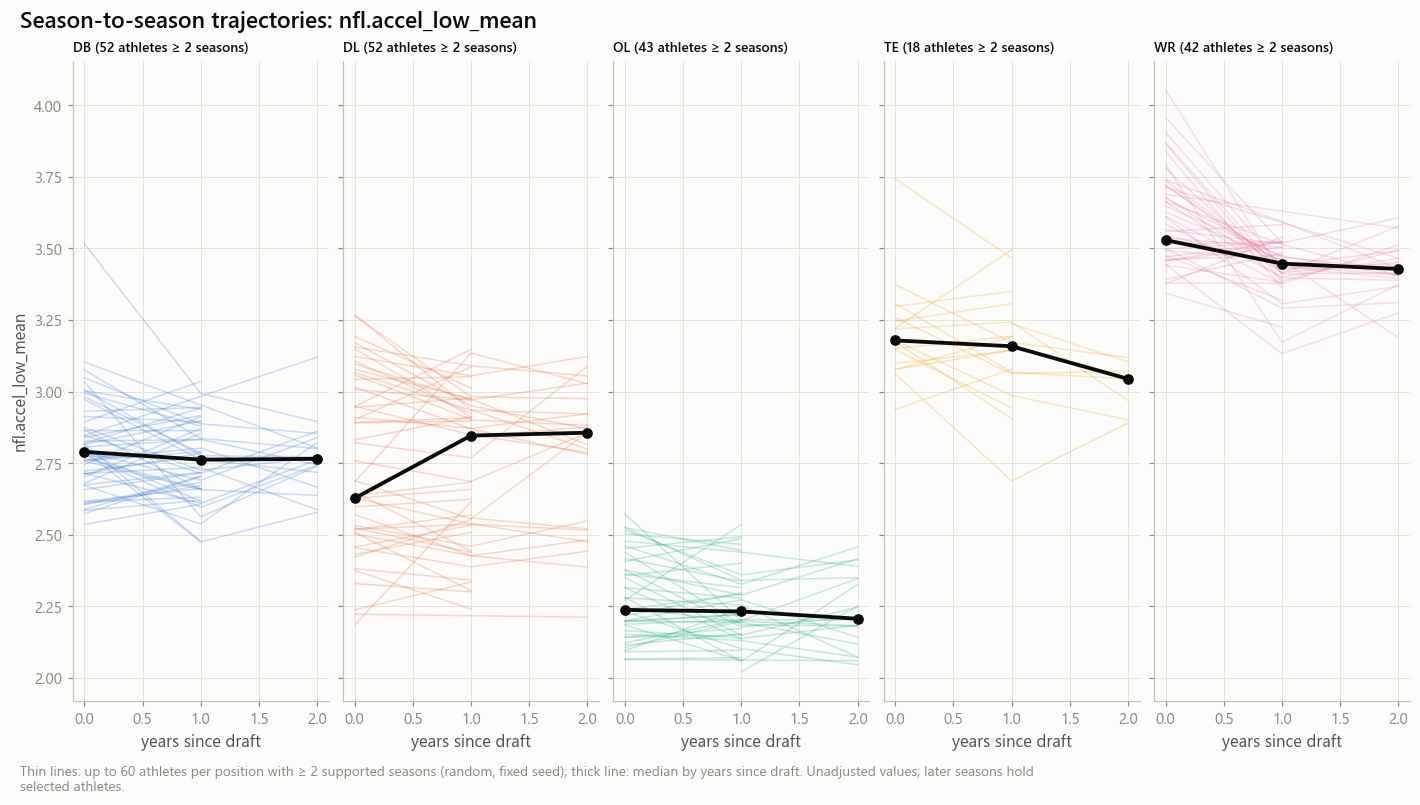

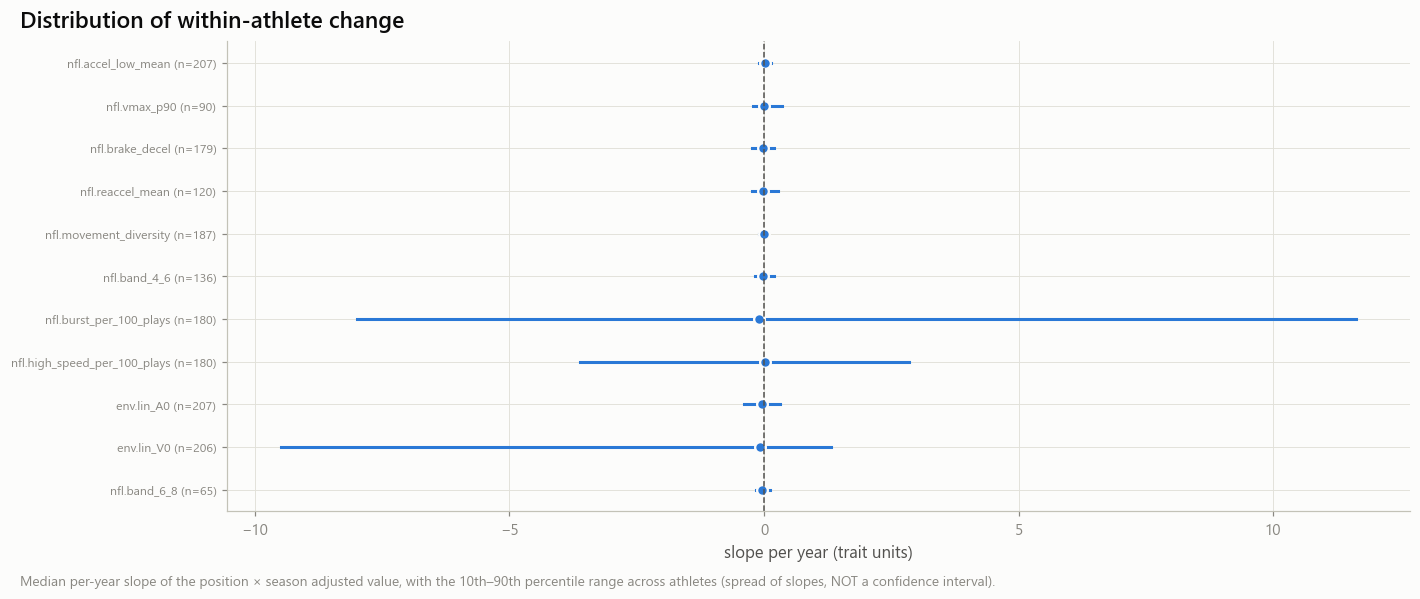

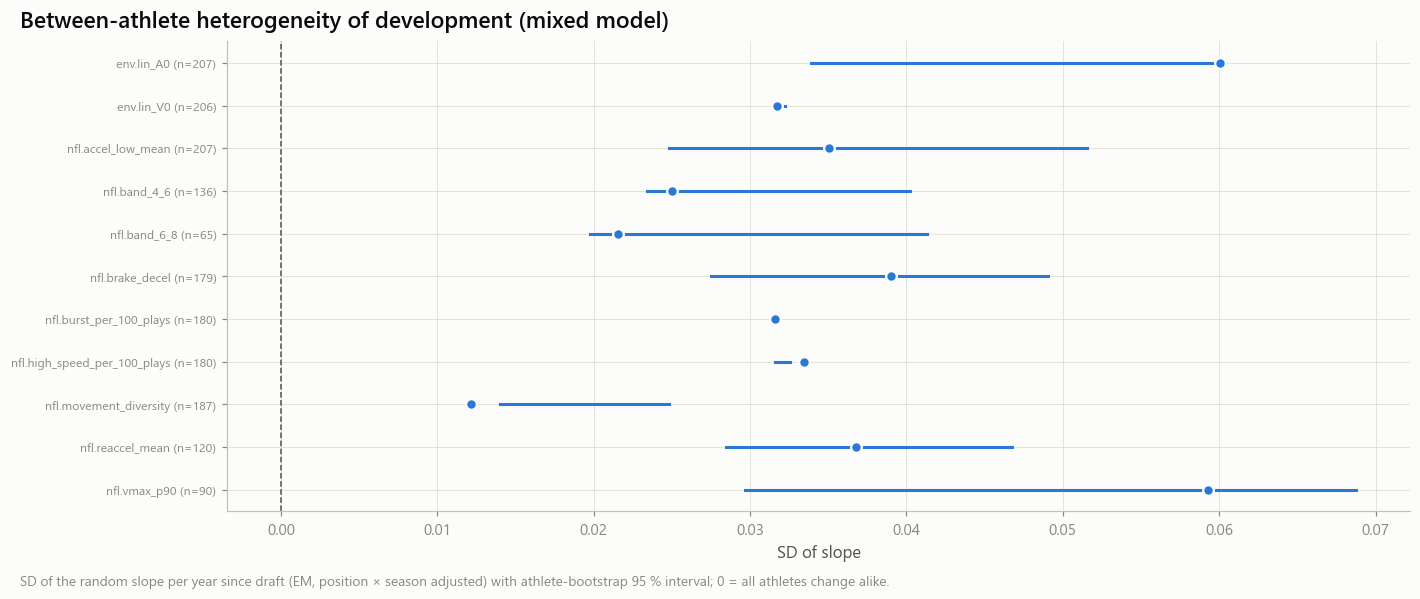

target_id,spearman_halves,n_athlete_seasons,median_change
str,f64,u32,f64
"""nfl.reaccel_mean""",0.464572,241,-0.046734
"""nfl.vmax_p90""",0.546519,187,-0.036689
"""nfl.brake_decel""",0.756281,474,-0.049618
"""nfl.band_4_6""",0.892149,338,-0.011286
"""nfl.band_6_8""",0.57376,127,-0.040699
"""nfl.accel_low_mean""",0.937162,597,0.002097


In [4]:
if FEASIBLE:
    pf = panel.filter(pl.col('trait').is_in(FEASIBLE))
    change = dv.within_change(pf, 'value_adj')
    mixed = dv.mixed_model_table(pf, C, n_boot=N_BOOT_LMM if not controls.smoke else 10, seed=C.seed)
    mixed_pos = dv.mixed_model_table(pf, C, n_boot=max(20, N_BOOT_LMM // 4) if not controls.smoke else 5, seed=C.seed, by_position=True)
    sel = dv.selection_table(pf, cd.wide(asm.foundation(store, 'm11_athlete_features')), ['forty.band_4_6_mean_accel', 'forty.phase_A0', 'forty.v_max_obs'])
    e2l = dv.early_to_later(pf, C, C.seed)
    for k, v in (('m11_development_change', change), ('m11_development_mixed', mixed), ('m11_development_mixed_by_position', mixed_pos), ('m11_development_selection', sel), ('m11_development_early_later', e2l)):
        W(v, k)
    with pl.Config(tbl_rows=-1, tbl_width_chars=240):
        display(mixed)
        display(e2l)
        display(sel)
    for trait in FEASIBLE[:3]:
        store.show(fg.fig_spaghetti(pf, trait, f'Season-to-season trajectories: {trait}', 'Thin lines: up to 60 athletes per position with ≥ 2 supported seasons (random, fixed seed); thick line: median by years since draft. Unadjusted values; later seasons hold selected athletes.', seed=C.seed),
                   f'AM11_D_01_spaghetti_{trait.replace(".", "_")}', {}, publication=True, source='m11_season_panel')
    ch = change.group_by('trait').agg(pl.col('slope_ols').median().alias('median'), pl.col('slope_ols').quantile(0.1, 'linear').alias('q10'), pl.col('slope_ols').quantile(0.9, 'linear').alias('q90'), pl.len().alias('n'))
    store.show(fg.fig_forest(ch.with_columns((pl.col('trait') + ' (n=' + pl.col('n').cast(pl.String) + ')').alias('label')), 'label', 'median', 'q10', 'q90', 'Distribution of within-athlete change',
                             'Median per-year slope of the position × season adjusted value, with the 10th–90th percentile range across athletes (spread of slopes, NOT a confidence interval).', 'slope per year (trait units)'),
               'AM11_D_02_change_distributions', {'change': ch}, publication=True, source='m11_development_change')
    mm = mixed.filter(pl.col('status') == 'computed') if 'status' in mixed.columns else mixed.clear()
    if mm.height:
        store.show(fg.fig_forest(mm.with_columns((pl.col('trait') + ' (n=' + pl.col('n_athletes').cast(pl.String) + ')').alias('label')), 'label', 'sd_slope', 'sd_slope_lo', 'sd_slope_hi',
                                 'Between-athlete heterogeneity of development (mixed model)', 'SD of the random slope per year since draft (EM, position × season adjusted) with athlete-bootstrap 95 % interval; 0 = all athletes change alike.', 'SD of slope'),
                   'AM11_D_03_slope_heterogeneity', {'mixed': mm}, publication=True, source='m11_development_mixed')
else:
    display(Markdown('**NOT_FEASIBLE** for multi-season models: too few athletes with ≥ 2 supported seasons. Alternative: within-season first-half vs second-half games.'))
    change = mixed = sel = e2l = pl.DataFrame()
alt = dv.within_season_panel(episodes, pairs, C)
W(alt, 'm11_within_season_panel')
if alt.height:
    w2 = alt.filter(pl.col('supported')).pivot(on='half', index=['nfl_id', 'season_year', 'target_id'], values='value').drop_nulls()
    if w2.width >= 5:
        w2 = w2.rename({w2.columns[-2]: 'first_half', w2.columns[-1]: 'second_half'})
        stab = w2.group_by('target_id').agg(pl.corr('first_half', 'second_half', method='spearman').alias('spearman_halves'), pl.len().alias('n_athlete_seasons'), (pl.col('second_half') - pl.col('first_half')).median().alias('median_change'))
        W(stab, 'm11_within_season_stability')
        display(stab)

## 3 · Combine features and NFL development (D4)

Spearman (bootstrap CI) of Combine features with first-season level, last-season level, per-year slope and |change|. Descriptive; selection into later seasons can create or hide relations.

trait,combine,relation,n_athletes,spearman,spearman_lo,spearman_hi,mde_r,reading
str,str,str,i64,f64,f64,f64,f64,str
"""env.lin_A0""","""forty.band_4_6_mean_accel""","""first_season_level""",323,0.623539,0.554863,0.691765,0.155345,"""association (interval excludes…"
"""env.lin_A0""","""forty.band_4_6_mean_accel""","""last_season_level""",323,0.609323,0.53117,0.678295,0.155345,"""association (interval excludes…"
"""env.lin_A0""","""forty.band_4_6_mean_accel""","""slope_per_year""",181,-0.067733,-0.19713,0.088084,0.206955,"""inconclusive (|r| below ≈ 0.21…"
"""env.lin_A0""","""forty.band_4_6_mean_accel""","""abs_change""",181,-0.041845,-0.23399,0.118876,0.206955,"""inconclusive (|r| below ≈ 0.21…"
"""env.lin_A0""","""forty.band_6_8_mean_accel""","""first_season_level""",323,0.678124,0.611641,0.733922,0.155345,"""association (interval excludes…"
"""env.lin_A0""","""forty.band_6_8_mean_accel""","""last_season_level""",323,0.695682,0.628182,0.743806,0.155345,"""association (interval excludes…"
"""env.lin_A0""","""forty.band_6_8_mean_accel""","""slope_per_year""",181,-0.060978,-0.191038,0.090854,0.206955,"""inconclusive (|r| below ≈ 0.21…"
"""env.lin_A0""","""forty.band_6_8_mean_accel""","""abs_change""",181,-0.059911,-0.246535,0.072293,0.206955,"""inconclusive (|r| below ≈ 0.21…"
"""env.lin_A0""","""forty.phase_A0""","""first_season_level""",323,0.344266,0.257059,0.437288,0.155345,"""association (interval excludes…"


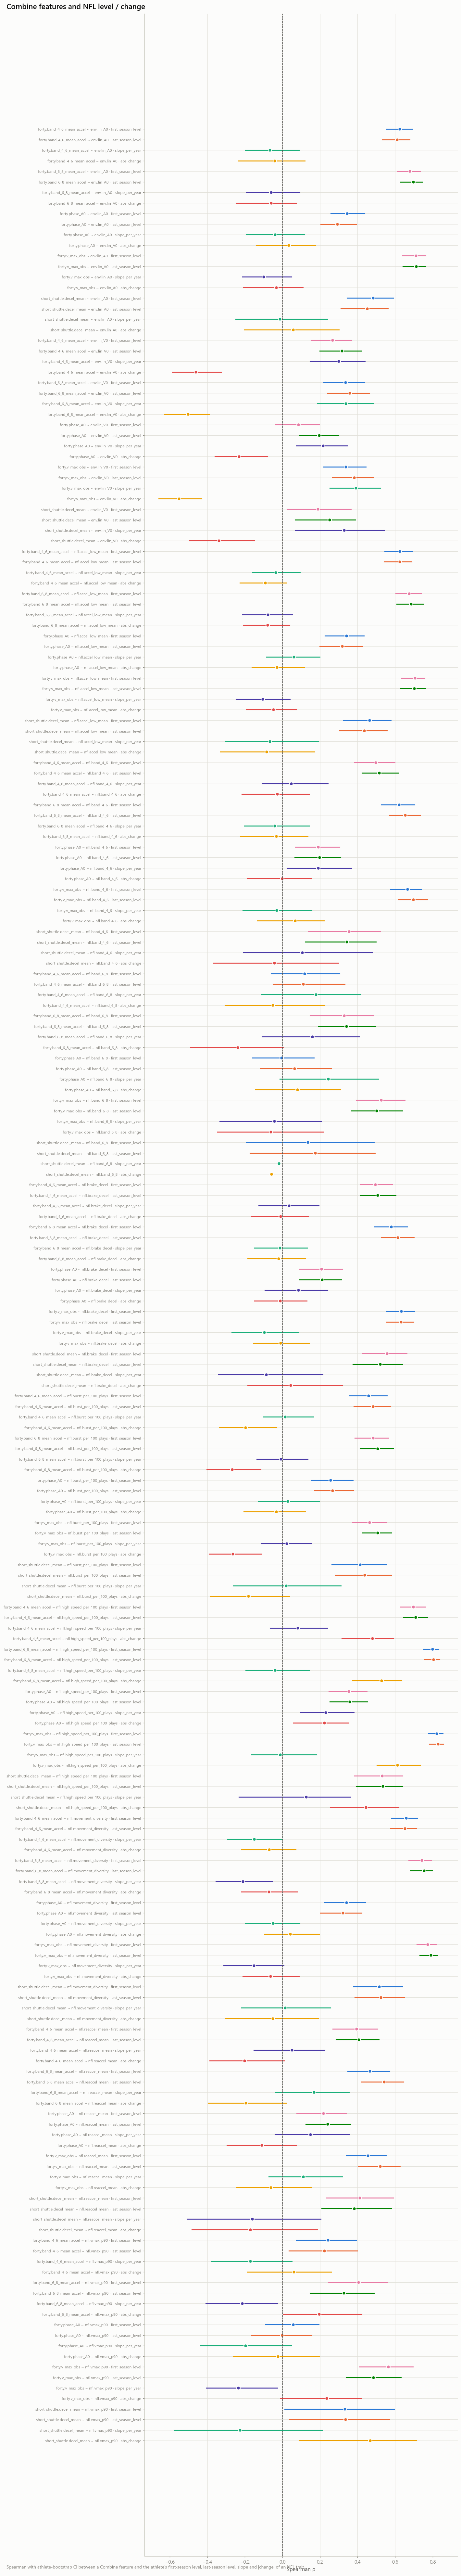

In [5]:
FEAT = ['forty.band_4_6_mean_accel', 'forty.band_6_8_mean_accel', 'forty.phase_A0', 'forty.v_max_obs', 'short_shuttle.decel_mean']
rel = dv.combine_relations(change, panel.filter(pl.col('trait').is_in(FEASIBLE)), cd.wide(asm.foundation(store, 'm11_athlete_features')), FEAT, C, C.seed) if FEASIBLE and change.height else pl.DataFrame()
W(rel, 'm11_development_relations')
if rel.height:
    with pl.Config(tbl_rows=60, tbl_width_chars=220):
        display(rel)
    rr = rel.filter(pl.col('n_athletes') >= C.min_athletes_limited).with_columns((pl.col('combine') + ' ~ ' + pl.col('trait') + ' · ' + pl.col('relation')).alias('label'))
    store.show(fg.fig_forest(rr, 'label', 'spearman', 'spearman_lo', 'spearman_hi', 'Combine features and NFL level / change',
                             'Spearman with athlete-bootstrap CI between a Combine feature and the athlete’s first-season level, last-season level, slope and |change| of an NFL trait.', 'Spearman ρ', color_by='relation'),
               'AM11_D_04_combine_relations', {'relations': rr}, publication=True, source='m11_development_relations')

## 11D — conclusion (supported_finding; run mode full; generated 2026-10-14T23:19:11Z)

### Research question
Do NFL movement characteristics change measurably across seasons, and are Combine features related to level or change?

### Hypothesis
Between-athlete variance of season-to-season change exceeds measurement noise.

### Sample
seasons [2023, 2024, 2025]; 401 athletes in the panel; multi-season traits: env.lin_A0, env.lin_V0, nfl.accel_low_mean, nfl.band_4_6, nfl.band_6_8, nfl.brake_decel, nfl.burst_per_100_plays, nfl.high_speed_per_100_plays, nfl.movement_diversity, nfl.reaccel_mean, nfl.vmax_p90.

### Main evidence
- env.lin_A0: slope SD 0.060 [0.034, 0.060], fixed slope -0.024 per year, n=207
- env.lin_V0: slope SD 0.032 [0.032, 0.032], fixed slope 3.960 per year, n=206
- nfl.accel_low_mean: slope SD 0.035 [0.025, 0.052], fixed slope 0.013 per year, n=207
- nfl.band_4_6: slope SD 0.025 [0.023, 0.040], fixed slope -0.012 per year, n=136
- nfl.band_6_8: slope SD 0.022 [0.020, 0.041], fixed slope -0.026 per year, n=65
- nfl.brake_decel: slope SD 0.039 [0.028, 0.049], fixed slope -0.007 per year, n=179
- nfl.burst_per_100_plays: slope SD 0.032 [0.032, 0.032], fixed slope 0.415 per year, n=180
- nfl.high_speed_per_100_plays: slope SD 0.033 [0.032, 0.033], fixed slope -0.283 per year, n=180
- nfl.movement_diversity: slope SD 0.012 [0.014, 0.025], fixed slope -0.002 per year, n=187
- nfl.reaccel_mean: slope SD 0.037 [0.028, 0.047], fixed slope -0.009 per year, n=120
- nfl.vmax_p90: slope SD 0.059 [0.030, 0.069], fixed slope 0.038 per year, n=90
- first → later season env.lin_A0: ρ 0.946 [0.923, 0.960] (n=207)
- first → later season env.lin_V0: ρ 0.674 [0.579, 0.763] (n=206)
- first → later season nfl.accel_low_mean: ρ 0.946 [0.927, 0.959] (n=207)
- first → later season nfl.band_4_6: ρ 0.931 [0.899, 0.952] (n=136)
- first → later season nfl.band_6_8: ρ 0.618 [0.448, 0.768] (n=65)
- first → later season nfl.brake_decel: ρ 0.781 [0.702, 0.844] (n=179)
- first → later season nfl.burst_per_100_plays: ρ 0.858 [0.805, 0.904] (n=180)
- first → later season nfl.high_speed_per_100_plays: ρ 0.942 [0.920, 0.958] (n=180)
- first → later season nfl.movement_diversity: ρ 0.938 [0.909, 0.958] (n=187)
- first → later season nfl.reaccel_mean: ρ 0.634 [0.494, 0.740] (n=120)
- first → later season nfl.vmax_p90: ρ 0.674 [0.525, 0.791] (n=90)

### Alternative explanations
- Role, scheme and snap share change across seasons; an envelope can move with opportunity, not ability.
- Athletes who stay in the league are selected (see the selection table).
- Tracking or filtering changes between seasons shift all athletes alike (removed by the position × season adjustment).

### Practical scouting relevance
Tells whether an NFL movement profile measured in year 1 is stable enough to describe a player, and whether athletes differ in how it develops.

### Limitations
- Short panels (few seasons per athlete).
- Random slopes on 2–3 points are weakly identified; intervals are wide.
- No age variable.

### Next experiment
- Extend the panel as new seasons are tracked.
- Model development within role (alignment) to separate usage from capacity.


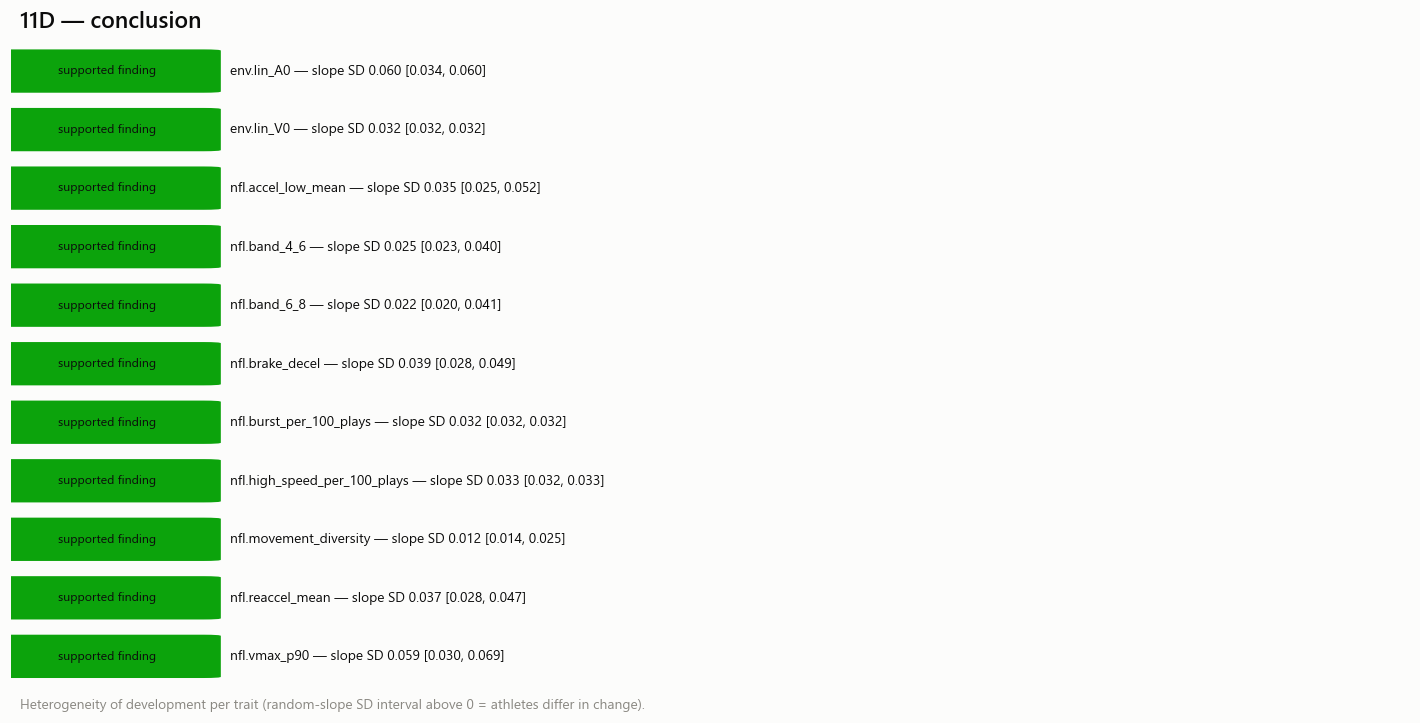

Send back: feasibility, mixed-model, early-to-later and relation tables, figures AM11_D_02 / 03, the conclusion.
Next: 11g_optimal_combine_drill_selection.ipynb


In [6]:
evid = [tn.evidence_row('nfl.movement_diversity', '11D', n_athletes=int(panel.filter(pl.col('trait') == 'nfl.movement_diversity')['nfl_id'].n_unique()),
                        nfl_reliability=(e2l.filter(pl.col('target_id') == 'x') if False else None), execution_mode=controls.run_mode, config_hash=C.hash(), note='NFL descriptor (Movement Vocabulary)')]
W(tn.evidence_frame(evid), 'm11_metric_evidence_11D')
mm = mixed.filter(pl.col('status') == 'computed') if mixed.height and 'status' in mixed.columns else pl.DataFrame()
verd = [('supported' if r['sd_slope_lo'] > 0.0 + 1e-12 else 'inconclusive') for r in mm.iter_rows(named=True)] if mm.height else []
status = m11c.NOT_FEASIBLE if not FEASIBLE else rp.comparison_status(verd)
facts = {'status': status, 'run_mode': controls.run_mode,
         'sample': f"seasons {seasons}; {panel['nfl_id'].n_unique()} athletes in the panel; multi-season traits: {', '.join(FEASIBLE) or 'none'}.",
         'evidence': [f"{r['trait']}: slope SD {rp.ci(r['sd_slope'], r['sd_slope_lo'], r['sd_slope_hi'])}, fixed slope {rp.fmt(r['slope'])} per year, n={r['n_athletes']}" for r in mm.iter_rows(named=True)]
                     + [f"first → later season {r['trait']}: ρ {rp.ci(r['spearman'], r['spearman_lo'], r['spearman_hi'])} (n={r['n_athletes']})" for r in (e2l.iter_rows(named=True) if e2l.height else [])],
         'alternatives': ['Role, scheme and snap share change across seasons; an envelope can move with opportunity, not ability.', 'Athletes who stay in the league are selected (see the selection table).', 'Tracking or filtering changes between seasons shift all athletes alike (removed by the position × season adjustment).'],
         'relevance': 'Tells whether an NFL movement profile measured in year 1 is stable enough to describe a player, and whether athletes differ in how it develops.',
         'limitations': ['Short panels (few seasons per athlete).', 'Random slopes on 2–3 points are weakly identified; intervals are wide.', 'No age variable.'],
         'next': ['Extend the panel as new seasons are tracked.', 'Model development within role (alignment) to separate usage from capacity.']}
md_ = rp.conclusion_markdown('11D', facts)
display(Markdown(md_))
rp.write_conclusion(store, '11D', md_)
rp.run_manifest(store, '11D', PROV, ['m11_season_panel', 'm11_development_mixed', 'm11_development_change', 'm11_development_relations'], status)
crow = pl.DataFrame([{'item': r['trait'], 'evidence': f"slope SD {rp.ci(r['sd_slope'], r['sd_slope_lo'], r['sd_slope_hi'])}", 'status': 'supported_finding' if r['sd_slope_lo'] > 0 else 'inconclusive'} for r in mm.iter_rows(named=True)]) if mm.height else pl.DataFrame([{'item': 'multi-season development', 'evidence': 'too few multi-season athletes', 'status': 'not_feasible'}])
store.show(fg.fig_conclusion(crow, '11D — conclusion', 'Heterogeneity of development per trait (random-slope SD interval above 0 = athletes differ in change).'), 'AM11_D_05_conclusion', {}, publication=True, source='m11_development_mixed')
print('Send back: feasibility, mixed-model, early-to-later and relation tables, figures AM11_D_02 / 03, the conclusion.')
print('Next: 11g_optimal_combine_drill_selection.ipynb')